# Assignment 5 — ANOVA and Simple Linear Regression
**Group members:** Daniel Munteanu, Josip Brljevic, Luca Mouawad, Zygmunt Tadeusz Kwasniewicz

In [ ]:
# py -m pip install scipy statsmodels matplotlib
from IPython.display import display, Markdown
import scipy.stats as stats
from statsmodels.stats.proportion import proportion_confint
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import math
import statsmodels.api as sm


# Part 1 — Composite strength across curing methods
#### The file *assignment05_composite_strength.csv* contains independent composite specimens cured by four methods. The response is `strength_mpa`; the factor is `curing_method`.

### a) Identify the population, observational unit, response, factor, and factor levels. Explain what additional design information would be needed for a causal claim about curing method.



### b) Report group sample sizes, means, and sample standard deviations. Create side‑by‑side boxplots and describe between‑group differences and within‑group variation.

### c) State the one‑way ANOVA hypotheses. Explain why a collection of unadjusted pairwise *t*‑tests is a poor default.

### d) Fit the classical one‑way model and produce an ANOVA table. Report sums of squares, degrees of freedom, mean squares, *F*, *p* and explain what the *F* ratio compares.

# Part 2 — Diagnostics, post‑hoc comparisons, and magnitude
#### Continue with the composite‑strength study.

### a) Diagnose independence from the study description and inspect within‑group errors using group spreads, residual‑versus‑fitted, and a QQ‑plot of residuals. Explain why the pooled raw response is not the correct normality diagnostic.

### b) Decide whether the classical common‑variance model is credible. Also run Welch's one‑way ANOVA as a sensitivity analysis and explain why it is not paired automatically with ordinary Tukey HSD.



### c) Calculate η² and interpret it as a descriptive fraction of observed squared variation, not causation.



### d) If the classical omnibus test is relevant and significant, perform Tukey HSD. Report simultaneous pairwise intervals and adjusted *p*‑values and identify which curing methods are distinguishable. Do not treat a non‑significant pair as proof of equal means.

### e) Write a recommendation in MPa that distinguishes the global question, specific pairwise differences, practical importance, and design limitations.

# Part 3 — Pump flow and energy use
#### The file *assignment05_pump_energy.csv* contains independent benchmark runs over an observed flow‑rate range. Let energy use be *Y* and flow rate be *x*, with the statistical model *Y* = β₀ + β₁ x + ε

### a) Identify the population, observational unit, response, predictor, and observed predictor range. Create a scatterplot and discuss whether a linear conditional‑mean model is plausible before fitting it.

### b) Fit an intercept model with statsmodels. Report and interpret β̂₀, β̂₁, residual standard deviation, Pearson correlation *r*, and R². Include units and discuss whether the intercept has a useful engineering interpretation.





### c) Verify that R² = r² for this simple intercept model. Explain what correlation and R² measure and what they do not establish.





### d) Test H₀: β₁ = 0 against a two‑sided alternative. Report the slope estimate, standard error, 95 % interval, *t*‑statistic, degrees of freedom, and *p*‑value. State the conclusion as an association, not automatically as causation.

# Part 4 — Regression diagnostics and prediction
#### Continue with the pump study.

In [107]:
pump_df = pd.read_csv("./assignment05_pump_energy.csv")
print(pump_df.head(1))
print(pump_df.tail(1))

   run_id  flow_l_min  energy_kwh
0       1        22.7       18.11
    run_id  flow_l_min  energy_kwh
54      55        97.0      47.294


In [91]:
x = pump_df["flow_l_min"]
y = pump_df["energy_kwh"]

X = sm.add_constant(x)
ols = sm.OLS(y, X).fit()
print(ols.summary(slim=True))

                            OLS Regression Results                            
Dep. Variable:             energy_kwh   R-squared:                       0.918
Model:                            OLS   Adj. R-squared:                  0.916
No. Observations:                  55   F-statistic:                     592.9
Covariance Type:            nonrobust   Prob (F-statistic):           1.90e-30
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          8.3180      1.051      7.916      0.000       6.211      10.426
flow_l_min     0.4092      0.017     24.349      0.000       0.375       0.443

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.


### a) Create residual‑versus‑fitted, residual‑versus‑run‑order, and normal QQ‑plots. Discuss linearity, constant spread, unusual observations, normal‑error approximation, and what the plots cannot establish about independence or sampling.

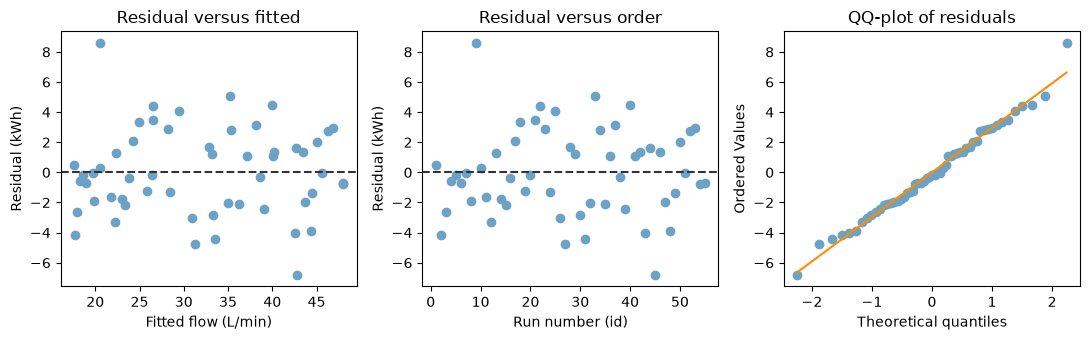


Thankfuly the residual errors do not shown any patterns and are relatively constant in their spread, thus we can conclude that the base requirements for using a linear model are not violated. We can notice an unusual observation at run number 9 and run number 46 (?), however with lack of context there is not much to do further.
The QQ plot shows that the errors are not particularly surprising and are approximately normally distributed.


In [130]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.5))
axes[0].scatter(ols.fittedvalues, ols.resid, color="#6CA2C6")
axes[0].axhline(0, color="0.2", linestyle="--")
axes[0].set_xlabel("Fitted flow (L/min)")
axes[0].set_ylabel("Residual (kWh)")
axes[0].set_title("Residual versus fitted")

axes[1].scatter(pump_df["run_id"], ols.resid, color="#6CA2C6")
axes[1].axhline(0, color="0.2", linestyle="--")
axes[1].set_xlabel("Run number (id)")
axes[1].set_ylabel("Residual (kWh)")
axes[1].set_title("Residual versus order")

stats.probplot(ols.resid, dist="norm", plot=axes[2])
axes[2].get_lines()[0].set_markerfacecolor("#6CA2C6")
axes[2].get_lines()[0].set_markeredgecolor("#6CA2C6")
axes[2].get_lines()[1].set_color("#FF8C00")
axes[2].set_title("QQ-plot of residuals")
plt.tight_layout()
plt.show()
display(Markdown(f"""
Thankfuly the residual errors do not shown any patterns and are relatively constant in their spread, thus we can conclude that the base requirements for using a linear model are not violated. We can notice an unusual observation at run number 9 and run number 46 (?), however with lack of context there is not much to do further.
The QQ plot shows that the errors are not particularly surprising and are approximately normally distributed.
"""))

### b) Calculate leverage and Cook’s distance. Identify the most influential run, investigate it rather than deleting it automatically, and explain what operational information you would seek.







In [51]:
infl = ols.get_influence()
leverage = infl.hat_matrix_diag
cooks = infl.cooks_distance[0]
flag = np.argmax(cooks)
display(Markdown(f"""
largest Cook's distance: \\
 id $={int(pump_df.loc[flag, 'run_id'])}$, leverage $= {leverage[flag]:.3f}$ \n
entry: \\
 {pump_df.loc[flag, :]} \n
 
On both of the residuals graphs it is immedietely obvious which of the points this is, as (alomost) all of the observations fit within a 6 distance from our OLS, while run number 9 scores above a whopping 8. Even when seeing jsut the head of the df above it was noticable, as it was a sudden jump in kWh from 18→29. This run would have to be looked into, and judged whether external factors influenced the measurment.
"""))


largest Cook's distance: \
 id $=9$, leverage $= 0.044$ 

entry: \
 run_id         9.000
flow_l_min    29.740
energy_kwh    29.085
Name: 8, dtype: float64 


On both of the residuals graphs it is immedietely obvious which of the points this is, as (alomost) all of the observations fit within a 6 distance from our OLS, while run number 9 scores above a whopping 8. Even when seeing jsut the head of the df above it was noticable, as it was a sudden jump in kWh from 18→29. This run would have to be looked into, and judged whether external factors influenced the measurment.


### c) At $x_0$ = 70 L/min, report the fitted mean energy, a 95% confidence interval for the mean energy, and a 95% prediction interval for one new run. Explain why the prediction interval is wider.



In [131]:
pred = ols.get_prediction([1, 70])
frame = pred.summary_frame(alpha=0.05)
mean = frame["mean"].values[0]
mean_ci_lower = frame["mean_ci_lower"].values[0]
mean_ci_upper = frame["mean_ci_upper"].values[0]
obs_ci_lower = frame["obs_ci_lower"].values[0]
obs_ci_upper = frame["obs_ci_upper"].values[0]

print(frame[["mean", "mean_ci_lower", "mean_ci_upper", "obs_ci_lower", "obs_ci_upper"]])
display(Markdown(f"""
mean $= {mean:.3f}$ \\
95% interval for entire mean $= {mean_ci_lower:.3f} - {mean_ci_upper:.3f}$ \\
95% interval for single run $= {obs_ci_lower:.3f} - {obs_ci_upper:.3f}$ \\
Since mean is calculated across many runs, it is expected that it will overtime settle down around our calculated mean, thats why its confidence interval is smaller, meanwhile a single prediction can be much more volatile
"""))

        mean  mean_ci_lower  mean_ci_upper  obs_ci_lower  obs_ci_upper
0  36.961036      36.067983      37.854089     31.000364     42.921708



mean $= 36.961$ \
95% interval for entire mean $= 36.068 - 37.854$ \
95% interval for single run $= 31.000 - 42.922$ \
Since mean is calculated across many runs, it is expected that it will overtime settle down around our calculated mean, thats why its confidence interval is smaller, meanwhile a single prediction can be much more volatile




### d) Explain why using this fitted line at 10 or 120 L/min would be extrapolation. State what evidence would be needed before extending the relationship outside the observed range.



In [90]:
display(Markdown(f"""
Since the data provided, on which we have fit the OLS only spans flows ranging from 22.7 to 97.0 L / min. That means we cannot say for certain that at either 10 or 120 L / min the model would continue to behave linearly. If we were assured that was the case, we could have extrapolated that information without much worry.
"""))


Since the data provided, on which we have fit the OLS only spans flows ranging from 22.7 to 97.0 L / min. That means we cannot say for certain that at either 10 or 120 L / min the model would continue to behave linearly. If we were assured that was the case, we could have extrapolated that information without much worry.




### e) Give a practical conclusion that includes slope in kWh per L min, uncertainty, residual variation, $R^2$, prediction uncertainty, and study‑design limitations.


In [126]:
i = []
t = 0

for x in range(23, 97):
    i.append(x)
    pred = ols.get_prediction([1, x])
    frame = pred.summary_frame(alpha=0.05)
    obs_ci_lower = frame["obs_ci_lower"].values[0]
    obs_ci_upper = frame["obs_ci_upper"].values[0]
    t += (obs_ci_upper - obs_ci_lower)
mean_prediction_uncertanty = t / len(i)
mean_prediction_uncertanty

np.float64(11.980524988577763)

In [128]:
slope = ols.params["flow_l_min"]
res_variation = ols.scale
r_squared = ols.rsquared
slope_ci_min, slope_ci_max = ols.conf_int().loc["flow_l_min"][0], ols.conf_int().loc["flow_l_min"][1]

display(Markdown(f"""
Across 55 runs of testing a pumps kWh against flow rate, required kWh increased by {slope} per 1 extra L / min \\
95% certainty interval: ${slope_ci_min} - {slope_ci_max}$ \\
residual variation $ = {res_variation}$ \\
$R^2 = {r_squared}$ \\
average prediction certainty interval has a length of ${mean_prediction_uncertanty}$
"""))


Across 55 runs of testing a pumps kWh against flow rate, required kWh increased by 0.4091858938939872 per 1 extra L / min \
95% certainty interval: $0.3754798499399219 - 0.4428919378480525$ \
residual variation $ = 8.63333879087679$ \
$R^2 = 0.9179432879664844$ \
average prediction certainty interval has a length of $11.980524988577763$


# Part 5 — AI‑use and conclusion
#### AI‑use
State which AI tools you used, what they contributed, what you changed or rejected, and how you verified the work. A short paragraph or table is sufficient.



#### Overall conclusion
Write approximately 150–250 words comparing ANOVA and regression as methods for a quantitative response. Explain how the type of predictor determines the question, how residuals are used in both analyses, and why statistical modelling does not by itself prove causation.


